# NLP Task 1

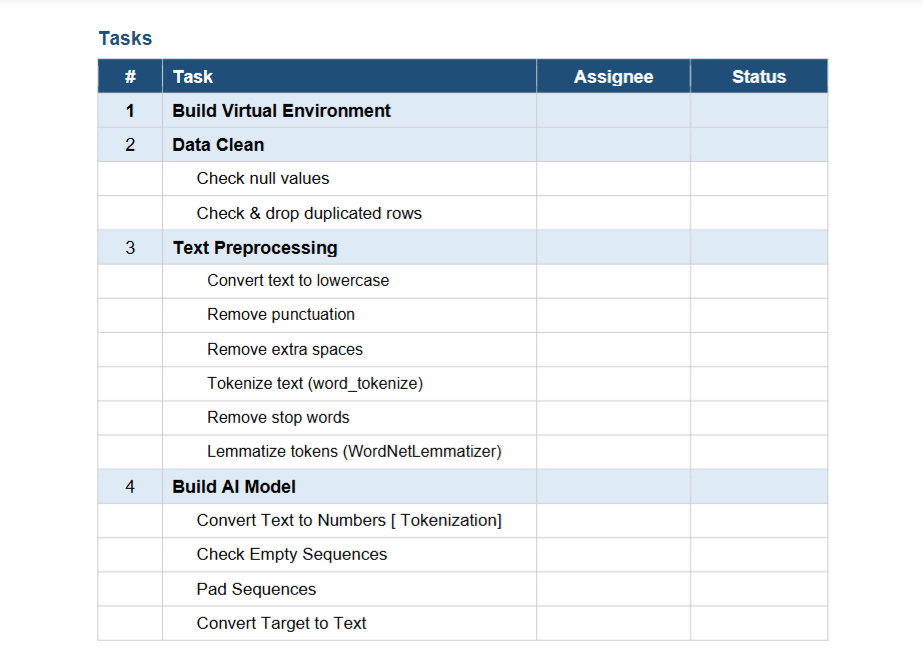

# 1. Build Virtual Environment

 create Virtual Environment using conda 
 

In [65]:
# Create a new conda environment for NLP tasks
#conda create --name nlp_tasks 

In [66]:
# Activate the NLP tasks environment
#conda activate nlp_tasks

## Setup 

In [67]:
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install nltk


%pip install tensorflow
%pip install google
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import string
import joblib

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download only required NLTK resources quietly to avoid long/hanging output
for pkg in ["punkt", "wordnet", "omw-1.4", "stopwords"]:
    nltk.download(pkg, quiet=True)

from tensorflow.keras.preprocessing.text import Tokenizer  # type: ignore
from tensorflow.keras.preprocessing.sequence import pad_sequences  # type: ignore


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


## - Data

In [ ]:
from pathlib import Path
import pandas as pd

cwd = Path.cwd().resolve()
candidate_roots = [cwd] + list(cwd.parents)

raw_data_dir = None
for root in candidate_roots:
    if (root / "data" / "raw" / "train.csv").exists():
        raw_data_dir = root / "data" / "raw"
        break

if raw_data_dir is None:
    raise FileNotFoundError("Could not find data/raw directory containing train.csv.")

train_path = raw_data_dir / "train.csv"
test_path = raw_data_dir / "test.csv"

print(f"Using train: {train_path}")
print(f"Using test : {test_path}")

test = pd.read_csv(test_path)
df = pd.read_csv(train_path)
df.sample(15)


Using train: ..\..\data\raw\train.csv
Using test : ..\..\data\raw\test.csv


,id,keyword,location,text,target
1075,1554,bomb,NaN,New Documents Found Pointing To Japan's WWII A...,1
2898,4163,drown,NaN,@cameronhigdon34 I can't drown my demons they ...,0
7333,10498,wildfire,NaN,Drones Under Fire: Officials Offer $75000 Rewa...,1
7292,10433,whirlwind,Atlanta - FAU class of '18,This past week has been an absolute whirlwind....,1
6987,10020,twister,NaN,Brain twister let drop up telly structuring ca...,0
3494,4993,explosion,New York,New Explosion-proof Tempered Glass Screen Prot...,0
248,353,annihilation,Subconscious LA,World Annihilation vs Self Transformation http...,0
7061,10115,upheaval,USA,Newberg upheaval: Jacque Betz responds 'lookin...,0
79,114,accident,"Njoro, Kenya",the pastor was not in the scene of the acciden...,1
2113,3037,death,To The Right of You!,Ted Cruz Bashes Obama Comparison GOP To Irania...,1


In [70]:
#from google.colab import sheets
#sheet = sheets.InteractiveSheet(df=df)

#2. Data Clean

Check null values

In [71]:
df.isnull().sum()

id             0
keyword       61
location    2533
text           0
target         0
dtype: int64

## Fill null values With NAN (thoses not important)

In [72]:
df.fillna("NAN", inplace=True)

,id,keyword,location,text,target
0,1,NAN,NAN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NAN,NAN,Forest fire near La Ronge Sask. Canada,1
2,5,NAN,NAN,All residents asked to 'shelter in place' are ...,1
3,6,NAN,NAN,"13,000 people receive #wildfires evacuation or...",1
4,7,NAN,NAN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NAN,NAN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NAN,NAN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NAN,NAN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NAN,NAN,Police investigating after an e-bike collided ...,1


## Check again after filling

In [73]:
df.isnull().sum()

id          0
keyword     0
location    0
text        0
target      0
dtype: int64

Check & drop duplicated rows

In [74]:
df.duplicated().sum()

np.int64(0)

### Check if there is same tweet (duplicated tweets)?

In [75]:
df.duplicated('text').sum()

np.int64(110)

### Show all duplicated tweets

In [76]:
#duplicated_df = df[df.duplicated('text', keep=False)].sort_values(by='text')
#sheet = sheets.InteractiveSheet(df=duplicated_df)

### Remove Duplicates

In [77]:
resolved_targets = (
    df.groupby('text')['target']
    .mean()
    .apply(lambda mean_val: 1 if mean_val >= 0.5 else 0)
)
df['target'] = df['text'].map(resolved_targets)
df.drop_duplicates(subset=['text'], keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)

In [78]:
df.duplicated('text').sum()

np.int64(0)

In [79]:
df.shape

(7503, 5)

#3. Text Preprocessing

Convert text to lowercase

In [80]:
df['text'] = df['text'].str.lower()

In [81]:
df['text'].sample(15)

3471    #climatechange eyewitness to extreme weather: ...
3434    exploring new worlds: three moments of an expl...
1651        it's always super awkward when worlds collide
4782    @theeconomist step one: get that mass murderer...
5317    you made my mood go from shitty af to panickin...
2392    it's so freeing to name a new .doc 'newidea' a...
6611    #usnwsgov special weather statement issued aug...
6889    @sarahmcpants @justjon i'll give him a titty t...
634          i've been by the pool all day #raisinfingers
5568    ud: rescue (structural collapse) - scott road ...
2784    @youssefyamani add fez weather to the equation...
7382    first wreck today. so so glad me and mom are o...
5274                                     it's don't panic
7057    gears of war 1!(preview member) come chat! xb1...
3400    the dress memes have officially exploded on th...
Name: text, dtype: str

Remove punctuation

In [82]:
table = str.maketrans('', '', string.punctuation)

# Apply translation directly to the 'text' column
df['text'] = df['text'].astype(str).str.translate(table)
df['text'].sample(15)

5096    but time began at last to obliterate the fresh...
3194    providence health amp services emergency servi...
3523    update 1russian food crematoria provoke outrag...
6840    if you have trouble getting motivated remember...
2112    12 of the deaths in redlight running crashes a...
6683    sometimes god uses sorrowful tragedy to set th...
1875    wrapup 2us cable tv companies shares crushed a...
6530                      natural lubrication metrofmtalk
6196    happy birthday lesleymariiee  i miss you so mu...
3387                             my head is gonna explode
791               tracy blight thank you for following me
2301    bbsnews latest 4 palestine amp israel   six pa...
7299    gunmen open fire on bus near el salvadors capi...
7432    wreckage conclusively confirmed as from mh370 ...
5088    holymileyray mooniighthunty focus on me is goi...
Name: text, dtype: str

Remove extra spaces

In [83]:
df['text'] = df['text'].astype(str).apply(lambda x: ' '.join(x.split()))
df['text'].head(15)

0     our deeds are the reason of this earthquake ma...
1                 forest fire near la ronge sask canada
2     all residents asked to shelter in place are be...
3     13000 people receive wildfires evacuation orde...
4     just got sent this photo from ruby alaska as s...
5     rockyfire update california hwy 20 closed in b...
6     flood disaster heavy rain causes flash floodin...
7     im on top of the hill and i can see a fire in ...
8     theres an emergency evacuation happening now i...
9      im afraid that the tornado is coming to our area
10          three people died from the heat wave so far
11    haha south tampa is getting flooded hah wait a...
12    raining flooding florida tampabay tampa 18 or ...
13                flood in bago myanmar we arrived bago
14    damage to school bus on 80 in multi car crash ...
Name: text, dtype: str

Tokenize text (word_tokenize)

In [84]:
df['text'] = df['text'].astype(str).apply(word_tokenize)

In [85]:
df['text'].sample(15)

5433    [top, link, reddits, new, content, policy, goe...
6876                [erictsunami, worry, about, yourself]
2052    [if, itûªs, a, war, you, came, to, see, you, ...
3431    [dont, think, ive, ever, been, this, close, to...
7011    [dramatic, video, shows, plane, landing, durin...
5501    [the, latest, more, homes, razed, by, northern...
6413    [dont, make, fun, of, them, for, trying, to, s...
304     [best, movie, youve, ever, seen, armageddon, h...
178     [news, twelve, feared, killed, in, pakistani, ...
6694    [this, is, a, tragedy, i, added, the, wrong, b...
3084    [also, my, iphone, charger, is, broken, and, i...
5514    [the, latest, more, homes, razed, by, northern...
1179    [ashes, 2015, australia, collapse, at, trent, ...
3972    [i, liked, a, youtube, video, httptcojk7npdpwr...
3097    [survival, kit, whistle, fire, starter, wire, ...
Name: text, dtype: object

Remove stop words

In [86]:
# stopwords are downloaded in the main imports cell


In [87]:
stop_words = set(stopwords.words('english'))

df['text'] = df['text'].apply(
    lambda tokens: [word for word in tokens if word.lower() not in stop_words]
)

df['text'].sample(15)

785     [city, program, help, turn, blight, greenspace...
3279    [tonight, quite, interesting, minutes, ago, fi...
3521    [things, become, terrible, great, ethiopian, f...
4619    [stuck, sleeper, train, 24, hours, derailing, ...
6302    [isis, claims, responsibility, saudi, mosque, ...
2659    [look, upon, three, methods, touching, obtaing...
4671    [phones, offers, gtgt, httptcobytbz8s5ux, 034,...
3663                    [worst, fear, httpstcoih8udz8mq3]
5307    [panic, attack, bc, dont, enough, money, drugs...
5768    [really, awful, cant, even, work, make, artist...
6811    [19, things, youll, understand, trouble, talki...
4513    [msnbc, fucking, idiot, gun, amp, hatchet, yet...
4455    [experienced, urogyn, trying, help, mesh, inju...
7387    [gop, debate, drinking, game, anyone, looking,...
2926    [family, mourns, drowning, superhero, toddler,...
Name: text, dtype: object

Lemmatize tokens (WordNetLemmatizer)

---



In [88]:
lemmatizer = WordNetLemmatizer()

df['text'] = df['text'].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)


In [89]:
df['text'].sample(15)

2663    [ignition, knock, detonation, sensor, connecto...
438                 [localarsonist, lmao, real, live, go]
1868    [jimmyfallon, crushed, squirrel, bone, mortar,...
7145    [slightly, doesnt, help, suh, wake, practice, ...
3880    [rt, grantfactory, grant, fund, weymouth, meet...
38      [barbados, bridgetown, jamaica, ûò, two, car,...
5491    [way, move, like, full, rainstorm, im, house, ...
366     [beyonce, pick, httptconnmqlz91o9, fan, army, ...
4390    [deosl86, xaviermarquis, hostage, meaningless,...
3622    [many, basket, charming, fatality, tonyakappes...
397                                [saynae, angel, arson]
1839           [master0fsloths, crush, httptcoszx6v0bbjf]
683     [blazingben, pattyds50, gwfrazee, joshuaassara...
7434    [wreckage, conclusively, confirmed, mh370, mal...
2583    [ford, truck, start, drive, destroyed, tornado...
Name: text, dtype: object

# 4. Build AI Model

Convert Text to Numbers [ Tokenization ]

In [90]:
# Initialize the Tokenizer
tokenizer = Tokenizer(oov_token='<OOV>')

# Fit on the list of lemmatized tokens
tokenizer.fit_on_texts(df['text'])

# Convert text to sequences of integers
df['sequences'] = tokenizer.texts_to_sequences(df['text'])

# Print vocabulary size and sample output
print(f'Vocabulary Size: {len(tokenizer.word_index)}')
display(df[['text', 'sequences']].head(5))

Vocabulary Size: 21280


,text,sequences
0,"[deed, reason, earthquake, may, allah, forgive...","[4072, 446, 162, 68, 1699, 4073, 7]"
1,"[forest, fire, near, la, ronge, sask, canada]","[106, 2, 163, 519, 6092, 6093, 1064]"
2,"[resident, asked, shelter, place, notified, of...","[1541, 1410, 1889, 471, 6094, 317, 191, 1889, ..."
3,"[13000, people, receive, wildfire, evacuation,...","[2569, 11, 4074, 76, 191, 379, 34]"
4,"[got, sent, photo, ruby, alaska, smoke, wildfi...","[32, 1065, 113, 6095, 1700, 185, 76, 6096, 102]"


In [91]:
df.sample(15)

,id,keyword,location,text,target,sequences
5610,8128,rescued,NAN,"[young, child, among, rescued, capsized, boat,...",1,"[979, 196, 1238, 313, 3882, 390, 879, 17654, 9..."
5481,7939,rainstorm,vancouver usa,"[nathanfillion, hardly]",0,"[17409, 5835]"
7264,10548,windstorm,NAN,"[windstorm, wsvr1686b, cover, vhull, runabout,...",0,"[378, 20874, 873, 20875, 20876, 390, 1555, 208..."
3375,4892,explode,Kajang ? UiTM Puncak Alam,"[head, gon, na, explode, soon]",0,"[201, 200, 81, 277, 435]"
124,183,aftershock,marysville ca,"[praise, god, ministry, tell, like, wdyouth, b...",0,"[6310, 119, 6311, 477, 3, 6312, 6313, 6314]"
6704,9749,tragedy,MÌ©xico,"[im, gunning, romance, never, thing, heartache...",0,"[5, 19780, 2203, 122, 92, 19781, 5587, 830, 51..."
3229,4695,engulfed,Coventry,"[feel, engulfed, low, selfimage, take, quiz, h...",0,"[111, 467, 623, 1296, 72, 841, 12761, 12762]"
6145,8906,snowstorm,"Louisiana, USA","[youre, snowstorm, im, purified, darkest, fair...",0,"[104, 582, 5, 18660, 5909, 4891, 3310, 18661, ..."
4788,6932,mass%20murderer,NAN,"[another, white, mass, murderer, thank, god, l...",1,"[114, 323, 95, 438, 425, 119, 127, 34, 16123]"
6477,9410,survivors,NAN,"[worldnews, fear, missing, migrant, med, bbc, ...",1,"[1424, 103, 240, 244, 1052, 795, 12, 23, 368, ..."


In [92]:
df.shape

(7503, 6)

Check Empty Sequences

In [93]:
empty_seqs_count = df['sequences'].apply(lambda x: len(x) == 0).sum()
print(f'Number of empty sequences: {empty_seqs_count}')

if empty_seqs_count > 0:
    display(df[df['sequences'].apply(lambda x: len(x) == 0)].head())

Number of empty sequences: 0


Pad Sequences

In [94]:
# Calculate sequence lengths
seq_lengths = df['sequences'].apply(len)
max_len = int(np.percentile(seq_lengths, 95))
print(f'95th percentile of sequence lengths (selected max_len): {max_len}')

# Pad sequences
X = pad_sequences(df['sequences'], maxlen=max_len, padding='post', truncating='post')
print(f'Shape of input tensor X: {X.shape}')

95th percentile of sequence lengths (selected max_len): 16
Shape of input tensor X: (7503, 16)


Convert Target to Text

In [95]:
# Extract the target labels
y = df['target'].values
print(f'Shape of target array y: {y.shape}')
print(f'Target class distribution:\n{df["target"].value_counts()}')

Shape of target array y: (7503,)
Target class distribution:
target
0    4302
1    3201
Name: count, dtype: int64


In [96]:
train_text = df["text"].apply(lambda tokens: " ".join(tokens))
test_text = test["text"].astype(str).str.lower()
test_text = test_text.str.translate(table)
test_text = test_text.apply(lambda x: " ".join(word_tokenize(x)))
test_text = test_text.apply(
    lambda text: " ".join([word for word in text.split() if word.lower() not in stop_words])
)
test_text = test_text.apply(
    lambda text: " ".join([lemmatizer.lemmatize(word) for word in text.split()])
)

y = df["target"]

# Export cleaned data to data/processed for downstream tasks (e.g. Task 2)
processed_dir = None
for root in candidate_roots:
    if (root / "data").exists():
        processed_dir = root / "data" / "processed"
        break

if processed_dir is not None:
    processed_dir.mkdir(parents=True, exist_ok=True)
    df_export = df.copy()
    df_export['cleaned_text'] = train_text
    export_path = processed_dir / "train_cleaned.csv"
    df_export[['id', 'keyword', 'location', 'text', 'cleaned_text', 'target']].to_csv(export_path, index=False)
    print(f"Exported cleaned dataset for Task 2 to: {export_path}")


In [97]:
X_train, X_valid, y_train, y_valid = train_test_split(
    train_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [98]:
# Build and train the Task 1 model (TF-IDF + Linear SVM)
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("svm", LinearSVC(random_state=42))
])

# Train on the training split
svm_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [99]:
# Evaluate model on validation split
y_valid_pred = svm_model.predict(X_valid)

accuracy = accuracy_score(y_valid, y_valid_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_valid, y_valid_pred))


Accuracy: 0.7761
Accuracy percentage: 77.61%

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.83      0.81       861
           1       0.75      0.70      0.73       640

    accuracy                           0.78      1501
   macro avg       0.77      0.77      0.77      1501
weighted avg       0.78      0.78      0.78      1501



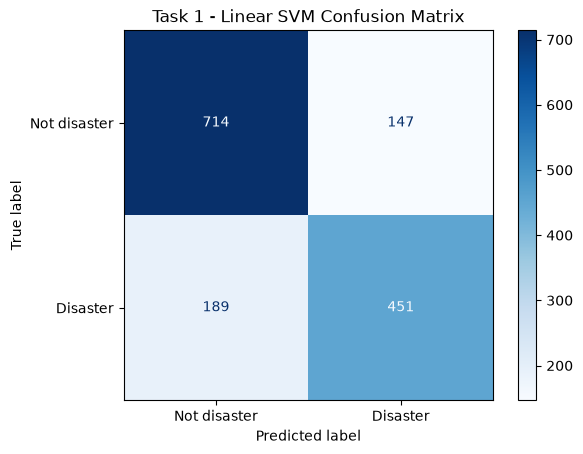

In [100]:
# Plot confusion matrix for validation predictions
cm = confusion_matrix(y_valid, y_valid_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not disaster", "Disaster"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Task 1 - Linear SVM Confusion Matrix")
plt.show()


In [101]:
from pathlib import Path

svm_model.fit(train_text, y)

cwd = Path.cwd().resolve()
candidate_roots = [cwd] + list(cwd.parents)

models_dir = None
for root in candidate_roots:
    if (root / "models").exists():
        models_dir = root / "models"
        break
    if (root / "data" / "raw").exists():
        models_dir = root / "models"
        break

if models_dir is None:
    models_dir = cwd / "models"

models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "task-1-linear-svc-tfidf-pipeline.joblib"
joblib.dump(svm_model, model_path)
print(f"Model saved to: {model_path}")

Model saved to: twitter-sentiment-analysis-nlp-tasks\models\task-1-linear-svc-tfidf-pipeline.joblib


In [102]:
# Load the saved model and run a quick sanity check prediction
loaded_model = joblib.load(model_path)
sample_pred = loaded_model.predict(X_valid.head(5))
print("Sample predictions from loaded model:", sample_pred)

Sample predictions from loaded model: [0 1 0 0 1]
